# 03 · Model selection & benchmarks

Predict **denied (1) vs approved (0)** for nationwide HMDA applications, comparing classic baselines,
tree ensembles, gradient-boosting libraries, and **deep-learning models built for tabular data**.

**Protocol**
* **Temporal split:** train on a 10% sample of **2024**, test on a 5% sample of **2025**. This is
  stricter than a random split; the denial rate shifts from 24.3% to 22.6% between years.
* Every model gets the same features from the `hmda.features` pipeline (see `02_feature_engineering`).
  Leaky post-decision fields and protected attributes are excluded.
* Hyperparameters are sensible library defaults, **not tuned**. These are baselines for model selection.
* Tables are saved to `reports/`.

Sections: 1 data · 2 benchmark (all models, full training sample) · 3 tabular deep learning ·
4 curves & calibration · 5 threshold · 6 training size · 7 fairness audit · 8 takeaways

In [1]:
%load_ext autoreload
%autoreload 2

import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter
from sklearn.calibration import calibration_curve
from sklearn.metrics import precision_recall_curve, roc_curve, roc_auc_score
from lightgbm import LGBMClassifier

from hmda.data import REPO_ROOT, approved_vs_denied, load_hmda
from hmda.features import HMDAFeatures, make_pipeline, split_xy
from hmda.models import AUDIT_COLS, benchmark, group_metrics, load_split, model_zoo, score
from hmda import plotting as hp

hp.use_style()
pd.set_option("display.float_format", "{:,.4f}".format)
REPORTS = REPO_ROOT / "reports"
REPORTS.mkdir(exist_ok=True)

## 1. Data

In [2]:
t0 = time.perf_counter()
X_train, y_train, X_test, y_test, audit_test = load_split(train_frac=0.10, test_frac=0.05)
print(f"loaded in {time.perf_counter() - t0:.0f}s")
print(f"train (2024): {len(X_train):,} rows, denial rate {y_train.mean():.3f}")
print(f"test  (2025): {len(X_test):,} rows, denial rate {y_test.mean():.3f}")
print(f"raw input columns: {X_train.shape[1]}")

loaded in 5s
train (2024): 864,090 rows, denial rate 0.243
test  (2025): 467,919 rows, denial rate 0.226
raw input columns: 42


## 2. Benchmark: all models on the full training sample

| Family | Models |
|---|---|
| reference | always-approve baseline (predicts the base rate) |
| linear | logistic regression (one-hot + scaled features) |
| bagged trees | random forest |
| gradient-boosted trees | sklearn HistGradientBoosting, LightGBM, XGBoost, CatBoost |

The tabular deep-learning models are in section 3; they're too slow on CPU to train on all ~860k rows.

In [3]:
results, fitted = benchmark(model_zoo(), X_train, y_train, X_test, y_test)
results.to_csv(REPORTS / "benchmark_results.csv")
results.sort_values("roc_auc", ascending=False)

Baseline (always approve)    AUC 0.5000  PR-AUC 0.2260  F1 0.0000  fit    4.0s


Logistic regression          AUC 0.8365  PR-AUC 0.6688  F1 0.5660  fit   17.9s


Random forest                AUC 0.8891  PR-AUC 0.7876  F1 0.6569  fit   27.5s


HistGradientBoosting         AUC 0.9059  PR-AUC 0.8243  F1 0.7197  fit   40.6s


LightGBM                     AUC 0.9079  PR-AUC 0.8279  F1 0.7232  fit   29.7s


XGBoost                      AUC 0.9067  PR-AUC 0.8251  F1 0.7191  fit   15.6s


CatBoost                     AUC 0.9061  PR-AUC 0.8245  F1 0.7189  fit   42.2s


,roc_auc,pr_auc,log_loss,brier,precision,recall,f1,fit_s,predict_s
model,,,,,,,,,
LightGBM,0.9079,0.8279,0.2798,0.0827,0.8652,0.6213,0.7232,29.7081,4.1569
XGBoost,0.9067,0.8251,0.2823,0.0835,0.8642,0.6157,0.7191,15.6462,2.1439
CatBoost,0.9061,0.8245,0.2828,0.0836,0.8661,0.6144,0.7189,42.2198,1.8073
HistGradientBoosting,0.9059,0.8243,0.2830,0.0836,0.8626,0.6174,0.7197,40.5698,2.8018
Random forest,0.8891,0.7876,0.3206,0.0957,0.8637,0.5300,0.6569,27.4655,2.6684
Logistic regression,0.8365,0.6688,0.3843,0.1192,0.7186,0.4669,0.5660,17.8553,2.5852
Baseline (always approve),0.5000,0.2260,0.5352,0.1752,0.0000,0.0000,0.0000,4.0015,1.7367


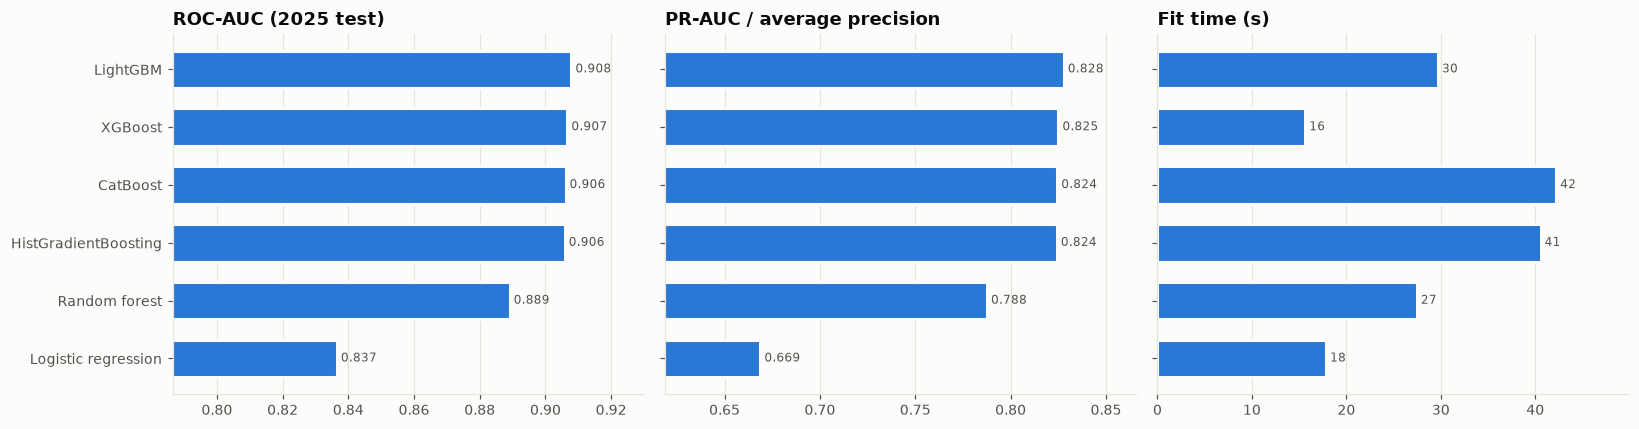

PR-AUC of a random classifier = test denial rate = 0.226


In [4]:
r = results.drop(index="Baseline (always approve)").sort_values("roc_auc")
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, (col, title, fmt) in zip(axes, [("roc_auc", "ROC-AUC (2025 test)", "{:.3f}"),
                                        ("pr_auc", "PR-AUC / average precision", "{:.3f}"),
                                        ("fit_s", "Fit time (s)", "{:.0f}")]):
    ax.barh(r.index, r[col], color=hp.BLUE, height=0.65, edgecolor=hp.SURFACE, linewidth=2)
    ax.grid(axis="y", visible=False)
    ax.set_title(title)
    lo = 0 if col == "fit_s" else r[col].min() - 0.05
    ax.set_xlim(lo, r[col].max() + (r[col].max() - lo) * 0.18)
    for i, v in enumerate(r[col]):
        ax.text(v, i, " " + fmt.format(v), va="center", fontsize=8, color=hp.TEXT_SECONDARY)
for ax in axes[1:]:
    ax.set_yticklabels([])
fig.tight_layout(); plt.show()
print(f"PR-AUC of a random classifier = test denial rate = {y_test.mean():.3f}")

## 3. Deep learning for tabular data

Two recent neural architectures designed for tabular data (via `pytabkit`, default hyperparameters):

* **RealMLP**: an MLP with tabular-specific defaults (robust scaling, numeric embeddings, tuned
  schedule). Holzmüller et al., *Better by Default*, NeurIPS 2024.
* **TabM**: a parameter-efficient ensemble of MLPs. Gorishniy et al., ICLR 2025.

They're far slower than gradient boosting (even on the Apple GPU via `mps`), so they train on a
**200k-row subsample of the same 2024 training data**. RealMLP uses library defaults; TabM is capped at
32 epochs. For a fair comparison, LightGBM, CatBoost, and logistic regression are
retrained on exactly the same rows. All models are scored on the same 2025 test set as in section 2.

In [5]:
import subprocess, sys
from hmda.tabular_dl import subsample_index

N_DL = 200_000
idx = subsample_index(len(X_train), N_DL)           # same rows the subprocess uses
X_small, y_small = X_train.iloc[idx], y_train[idx]
print(f"subsample: {N_DL:,} rows of the 2024 training sample (denial rate {y_small.mean():.3f})")

# Tree/linear models on the same rows, in this process
zoo = model_zoo()
gbm_results, _ = benchmark({n: zoo[n] for n in ["Logistic regression", "LightGBM", "CatBoost"]},
                           X_small, y_small, X_test, y_test)

# Tabular DL in a separate process: PyTorch deadlocks on macOS once LightGBM/XGBoost/CatBoost
# have loaded their OpenMP runtimes in the same process (see src/hmda/tabular_dl.py).
run = subprocess.run([sys.executable, "-m", "hmda.tabular_dl", "--rows", str(N_DL)],
                     capture_output=True, text=True, cwd=REPO_ROOT)
print("\n".join(l for l in run.stdout.splitlines() if not l.startswith("Columns classified")))
assert run.returncode == 0, run.stderr[-2000:]

dl_results = pd.concat([gbm_results, pd.read_csv(REPORTS / "tabular_dl_results.csv", index_col="model")])
dl_results.to_csv(REPORTS / "same_rows_comparison.csv")
dl_results.sort_values("roc_auc", ascending=False)

subsample: 200,000 rows of the 2024 training sample (denial rate 0.243)


Logistic regression          AUC 0.8347  PR-AUC 0.6662  F1 0.5645  fit    4.0s


LightGBM                     AUC 0.8979  PR-AUC 0.8119  F1 0.7075  fit   22.2s


CatBoost                     AUC 0.8986  PR-AUC 0.8120  F1 0.7057  fit   11.9s


training on 200,000 rows, testing on 467,919, device=mps
RealMLP (tabular DL)         AUC 0.8938  PR-AUC 0.8043  F1 0.7018  fit  397.3s
TabM (tabular DL)            AUC 0.8945  PR-AUC 0.8073  F1 0.6983  fit  432.5s
wrote /Users/henryolson/ml-final-project/reports/tabular_dl_results.csv


,roc_auc,pr_auc,log_loss,brier,precision,recall,f1,fit_s,predict_s
model,,,,,,,,,
CatBoost,0.8986,0.8120,0.2936,0.0869,0.8590,0.5988,0.7057,11.8553,1.8731
LightGBM,0.8979,0.8119,0.2939,0.0870,0.8513,0.6053,0.7075,22.2150,4.4929
TabM (tabular DL),0.8945,0.8073,0.2979,0.0883,0.8577,0.5888,0.6983,432.4529,27.0358
RealMLP (tabular DL),0.8938,0.8043,0.3084,0.0897,0.8467,0.5992,0.7018,397.3499,4.3285
Logistic regression,0.8347,0.6662,0.3861,0.1197,0.7176,0.4652,0.5645,4.0034,2.4830


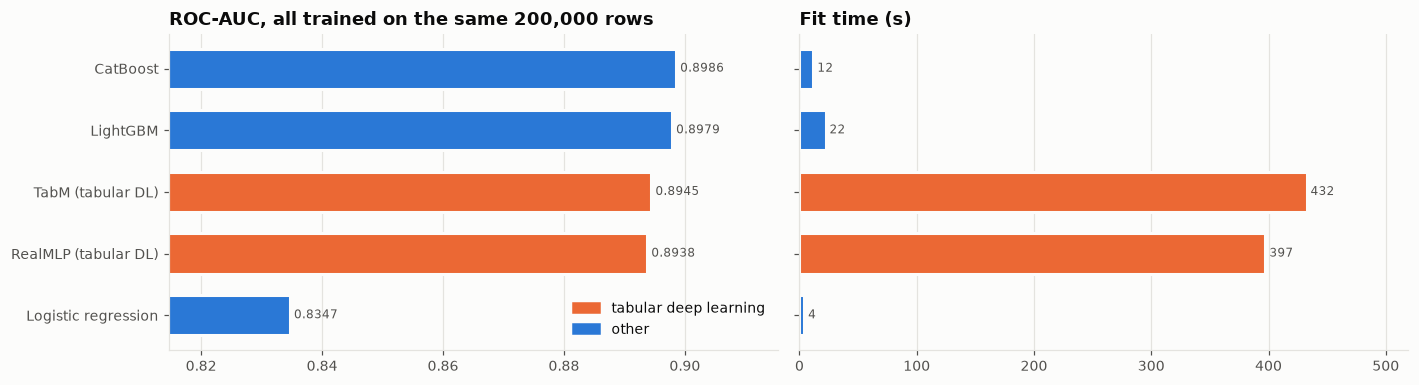

In [6]:
r = dl_results.sort_values("roc_auc")
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 3.6))
colors = [hp.ORANGE if "tabular DL" in n else hp.BLUE for n in r.index]
for ax, col, title, fmt in [(ax1, "roc_auc", f"ROC-AUC, all trained on the same {N_DL:,} rows", "{:.4f}"),
                            (ax2, "fit_s", "Fit time (s)", "{:.0f}")]:
    ax.barh(r.index, r[col], color=colors, height=0.65, edgecolor=hp.SURFACE, linewidth=2)
    ax.grid(axis="y", visible=False); ax.set_title(title)
    lo = 0 if col == "fit_s" else r[col].min() - 0.02
    ax.set_xlim(lo, r[col].max() + (r[col].max() - lo) * 0.2)
    for i, v in enumerate(r[col]):
        ax.text(v, i, " " + fmt.format(v), va="center", fontsize=8, color=hp.TEXT_SECONDARY)
ax2.set_yticklabels([])
from matplotlib.patches import Patch
ax1.legend(handles=[Patch(color=hp.ORANGE, label="tabular deep learning"), Patch(color=hp.BLUE, label="other")],
           loc="lower right")
fig.tight_layout(); plt.show()

## 4. ROC / PR curves and calibration

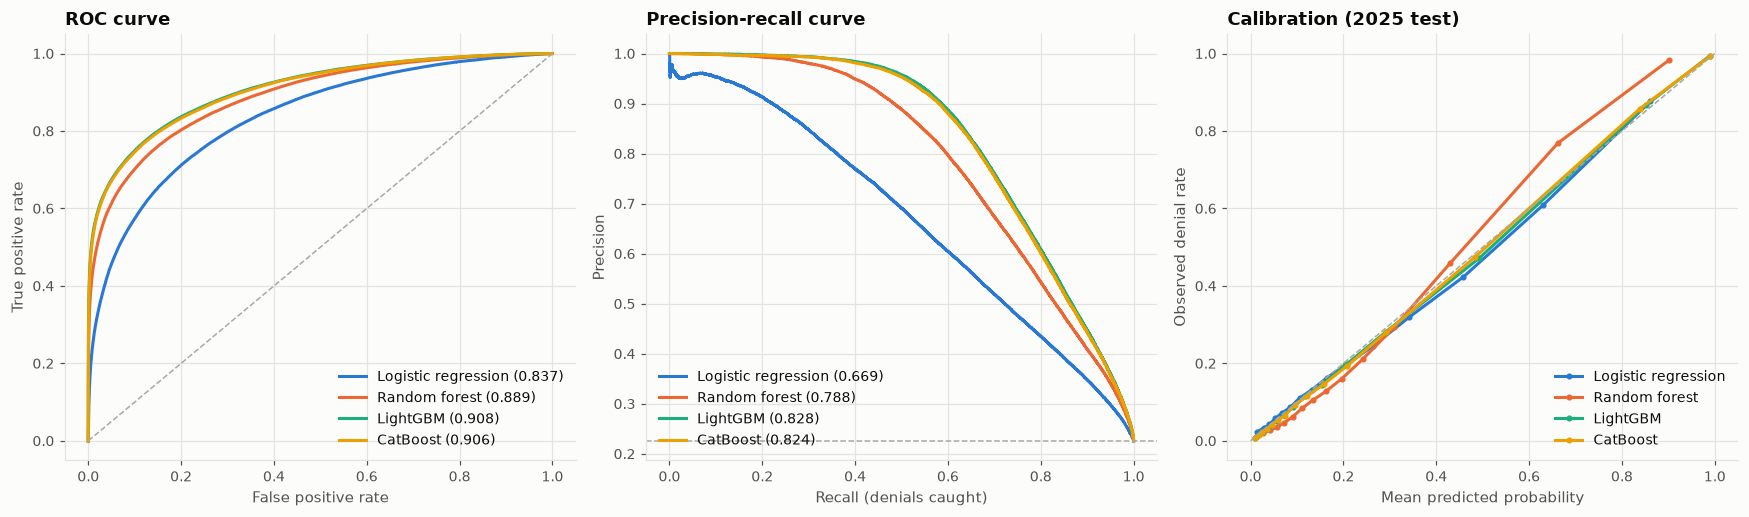

In [7]:
show = ["Logistic regression", "Random forest", "LightGBM", "CatBoost"]   # 4 series max per chart
probs = {name: fitted[name].predict_proba(X_test)[:, 1] for name in fitted}

fig, axes = plt.subplots(1, 3, figsize=(16, 4.8))
for color, name in zip(hp.SERIES, show):
    fpr, tpr, _ = roc_curve(y_test, probs[name])
    axes[0].plot(fpr, tpr, color=color, label=f"{name} ({results.loc[name, 'roc_auc']:.3f})")
    prec, rec, _ = precision_recall_curve(y_test, probs[name])
    axes[1].plot(rec, prec, color=color, label=f"{name} ({results.loc[name, 'pr_auc']:.3f})")
    frac_pos, mean_pred = calibration_curve(y_test, probs[name], n_bins=15, strategy="quantile")
    axes[2].plot(mean_pred, frac_pos, color=color, marker="o", markersize=3, label=name)
axes[0].plot([0, 1], [0, 1], color=hp.MUTED, lw=1, ls="--")
axes[0].set(title="ROC curve", xlabel="False positive rate", ylabel="True positive rate")
axes[1].axhline(y_test.mean(), color=hp.MUTED, lw=1, ls="--")
axes[1].set(title="Precision-recall curve", xlabel="Recall (denials caught)", ylabel="Precision")
axes[2].plot([0, 1], [0, 1], color=hp.MUTED, lw=1, ls="--")
axes[2].set(title="Calibration (2025 test)", xlabel="Mean predicted probability", ylabel="Observed denial rate")
for ax in axes:
    ax.legend(loc="lower right" if ax is not axes[1] else "lower left")
fig.tight_layout(); plt.show()

## 5. Choosing a decision threshold

In [8]:
best = results.drop(index="Baseline (always approve)")["roc_auc"].idxmax()
print("best model by ROC-AUC:", best)

# Pick the F1-maximizing threshold on held-out 2024 data (not the test set), then apply it to 2025.
val = approved_vs_denied(load_hmda(years=[2024], actions=[1, 2, 3], columns=HMDAFeatures().input_cols(),
                                   sample=0.02, sample_offset=0.10))   # disjoint from the 10% train sample
X_val, y_val = split_xy(val)
p_val = fitted[best].predict_proba(X_val)[:, 1]
prec, rec, thr = precision_recall_curve(y_val, p_val)
f1 = 2 * prec * rec / np.clip(prec + rec, 1e-9, None)
t_best = float(thr[np.argmax(f1[:-1])])
print(f"validation rows: {len(X_val):,}; F1-optimal threshold on 2024 validation: {t_best:.3f}")

cmp = pd.DataFrame({f"threshold 0.5": score(y_test, probs[best], 0.5),
                    f"threshold {t_best:.3f}": score(y_test, probs[best], t_best)}).T
cmp[["precision", "recall", "f1"]]

best model by ROC-AUC: LightGBM


validation rows: 172,401; F1-optimal threshold on 2024 validation: 0.367


,precision,recall,f1
threshold 0.5,0.8652,0.6213,0.7232
threshold 0.367,0.7825,0.6847,0.7303


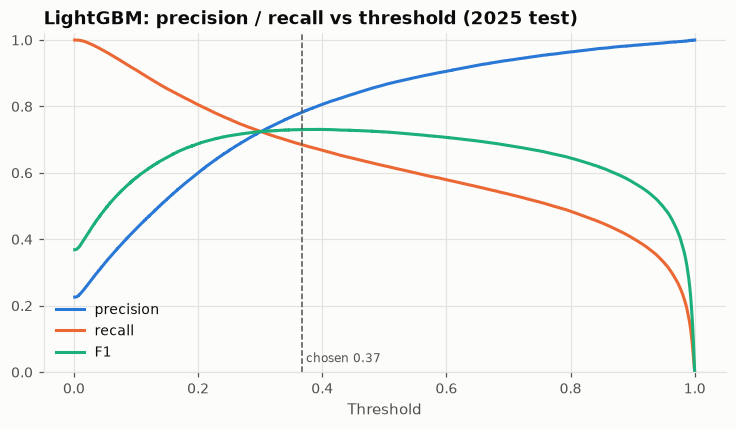

In [9]:
prec_t, rec_t, thr_t = precision_recall_curve(y_test, probs[best])
fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(thr_t, prec_t[:-1], color=hp.BLUE, label="precision")
ax.plot(thr_t, rec_t[:-1], color=hp.ORANGE, label="recall")
f1_t = 2 * prec_t * rec_t / np.clip(prec_t + rec_t, 1e-9, None)
ax.plot(thr_t, f1_t[:-1], color=hp.AQUA, label="F1")
ax.axvline(t_best, color=hp.TEXT_SECONDARY, lw=1, ls="--")
ax.text(t_best, 0.03, f" chosen {t_best:.2f}", fontsize=8, color=hp.TEXT_SECONDARY)
ax.set(title=f"{best}: precision / recall vs threshold (2025 test)", xlabel="Threshold", ylim=(0, 1.02))
ax.legend(loc="lower left")
plt.show()

## 6. Does more training data help? (LightGBM)

   1% of 2024 (   86,722 rows): AUC 0.8889  fit 21s


   3% of 2024 (  259,480 rows): AUC 0.9008  fit 24s


  10% of 2024 (  864,090 rows): AUC 0.9079  fit 32s


  30% of 2024 (2,590,534 rows): AUC 0.9119  fit 53s


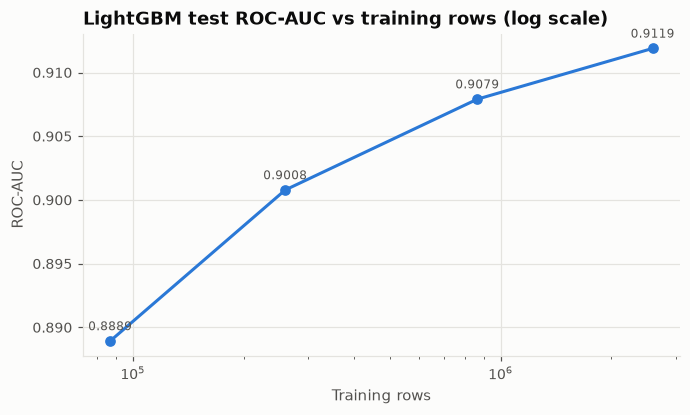

In [10]:
lgbm_spec = model_zoo()["LightGBM"]
curve = []
for frac in [0.01, 0.03, 0.10, 0.30]:
    if frac == 0.10:
        X_f, y_f = X_train, y_train
    else:
        d = approved_vs_denied(load_hmda(years=[2024], actions=[1, 2, 3],
                                         columns=HMDAFeatures().input_cols(), sample=frac))
        X_f, y_f = split_xy(d)
    res, _ = benchmark({"LightGBM": lgbm_spec}, X_f, y_f, X_test, y_test, verbose=False)
    curve.append({"train_frac": frac, "train_rows": len(X_f), **res.iloc[0][["roc_auc", "pr_auc", "fit_s"]]})
    print(f"{frac:>5.0%} of 2024 ({len(X_f):>9,} rows): AUC {curve[-1]['roc_auc']:.4f}  fit {curve[-1]['fit_s']:.0f}s")
curve = pd.DataFrame(curve)
del X_f, y_f, d

fig, ax = plt.subplots(figsize=(7, 3.8))
ax.plot(curve["train_rows"], curve["roc_auc"], marker="o", color=hp.BLUE)
ax.set_xscale("log")
ax.set(title="LightGBM test ROC-AUC vs training rows (log scale)", xlabel="Training rows", ylabel="ROC-AUC")
for _, r in curve.iterrows():
    ax.annotate(f"{r.roc_auc:.4f}", (r.train_rows, r.roc_auc), textcoords="offset points", xytext=(0, 7),
                ha="center", fontsize=8, color=hp.TEXT_SECONDARY)
plt.show()

## 7. Fairness audit (best model, chosen threshold)

In [11]:
p_best = probs[best]
race = group_metrics(y_test, p_best, audit_test["derived_race"], threshold=t_best)
sex = group_metrics(y_test, p_best, audit_test["derived_sex"], threshold=t_best)
display(race)
display(sex)
race.to_csv(REPORTS / "fairness_by_race.csv")

,n,actual_denial_rate,mean_predicted_prob,flagged_rate,roc_auc,false_positive_rate,false_negative_rate
group,,,,,,,
White,303506,0.2029,0.2134,0.1771,0.9050,0.0521,0.3317
Race Not Available,82316,0.2555,0.2489,0.2246,0.9126,0.0618,0.3012
Black or African American,38395,0.3531,0.3321,0.3164,0.8982,0.0909,0.2704
Asian,27674,0.2051,0.2071,0.1727,0.9147,0.0382,0.3061
Joint,10312,0.1816,0.1830,0.1505,0.9038,0.0406,0.3545
American Indian or Alaska Native,3327,0.3475,0.3265,0.3078,0.9127,0.0751,0.2552
2 or more minority races,1219,0.3585,0.3388,0.3183,0.9046,0.0806,0.2563
Native Hawaiian or Other Pacific Islander,1071,0.3417,0.3275,0.3081,0.9137,0.0780,0.2486


,n,actual_denial_rate,mean_predicted_prob,flagged_rate,roc_auc,false_positive_rate,false_negative_rate
group,,,,,,,
Joint,162198,0.1701,0.1754,0.1389,0.9065,0.0365,0.3617
Male,159510,0.2459,0.2486,0.2156,0.9021,0.0626,0.3153
Female,103579,0.2725,0.2802,0.2516,0.9084,0.0737,0.2734
Sex Not Available,42632,0.2508,0.2441,0.2239,0.9125,0.0665,0.3058


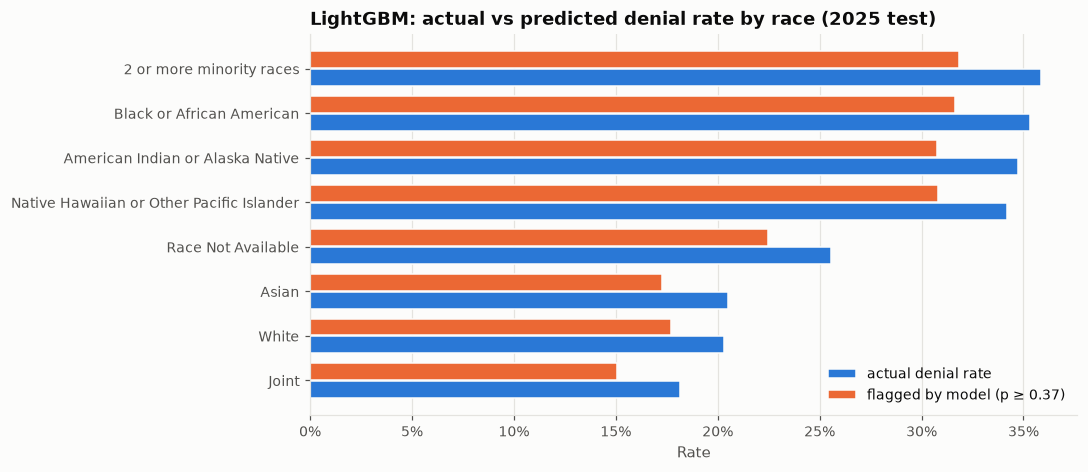

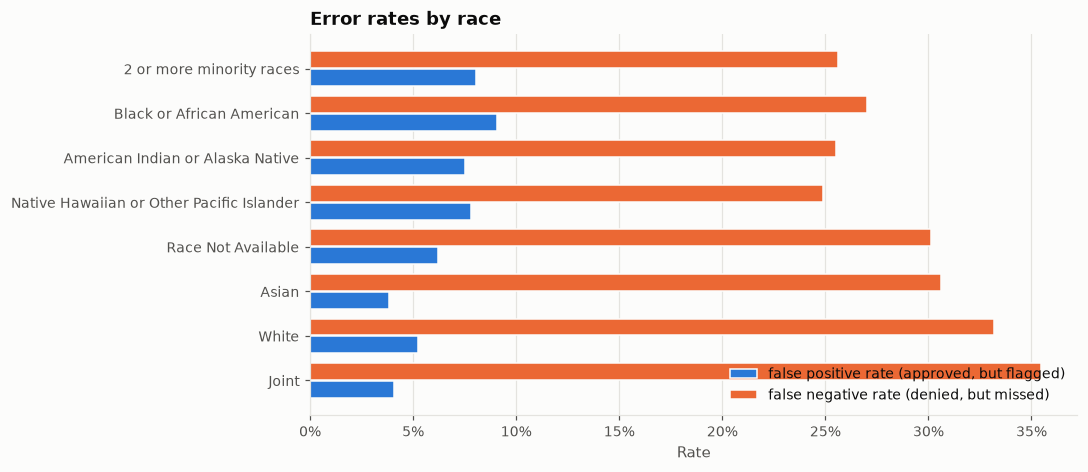

In [12]:
d = race.sort_values("actual_denial_rate")
y = np.arange(len(d))
fig, ax = plt.subplots(figsize=(9, 4.5))
ax.barh(y - 0.2, d["actual_denial_rate"], height=0.38, color=hp.BLUE, label="actual denial rate",
        edgecolor=hp.SURFACE, linewidth=1)
ax.barh(y + 0.2, d["flagged_rate"], height=0.38, color=hp.ORANGE, label=f"flagged by model (p ≥ {t_best:.2f})",
        edgecolor=hp.SURFACE, linewidth=1)
ax.set_yticks(y, d.index)
ax.xaxis.set_major_formatter(PercentFormatter(1.0, decimals=0))
ax.grid(axis="y", visible=False)
ax.set(title=f"{best}: actual vs predicted denial rate by race (2025 test)", xlabel="Rate")
ax.legend(loc="lower right")
plt.show()

fig, ax = plt.subplots(figsize=(9, 4.5))
ax.barh(y - 0.2, d["false_positive_rate"], height=0.38, color=hp.BLUE, label="false positive rate (approved, but flagged)",
        edgecolor=hp.SURFACE, linewidth=1)
ax.barh(y + 0.2, d["false_negative_rate"], height=0.38, color=hp.ORANGE, label="false negative rate (denied, but missed)",
        edgecolor=hp.SURFACE, linewidth=1)
ax.set_yticks(y, d.index)
ax.xaxis.set_major_formatter(PercentFormatter(1.0, decimals=0))
ax.grid(axis="y", visible=False)
ax.set(title="Error rates by race", xlabel="Rate")
ax.legend(loc="lower right")
plt.show()

## 8. Takeaways

Train: 864k decided applications (10% of 2024). Test: 468k (5% of 2025). Untuned defaults.

**1. Gradient boosting wins, and the four libraries are nearly tied.**

| Model | ROC-AUC | PR-AUC | Log loss | Fit |
|---|---|---|---|---|
| **LightGBM** | **0.908** | **0.828** | **0.280** | 30 s |
| XGBoost | 0.907 | 0.825 | 0.282 | 16 s |
| CatBoost | 0.906 | 0.825 | 0.283 | 42 s |
| HistGradientBoosting | 0.906 | 0.824 | 0.283 | 41 s |
| Random forest | 0.889 | 0.788 | 0.321 | 27 s |
| Logistic regression | 0.837 | 0.669 | 0.384 | 18 s |
| Baseline (always approve) | 0.500 | 0.226 | 0.535 | n/a |

**LightGBM is selected** for the next stage. XGBoost is a close, faster alternative (−0.001 AUC in half the time).

**2. Tabular deep learning is competitive but doesn't beat boosting here.** Trained on the same 200k rows,
TabM (0.8945) and RealMLP (0.8938) land ~0.004 AUC behind CatBoost (0.8986) and LightGBM (0.8979). They
also take 20–35× longer to train (~7 min each on the Apple GPU vs 12–22 s). With defaults and this
feature set, they're not worth the cost. Tuning them, or ensembling with a GBM, is optional follow-up work.

**3. Probabilities are well calibrated** for the boosting models and logistic regression (curves on the
diagonal). Random forest under-predicts at the high end.

**4. Threshold.** The F1-optimal threshold chosen on held-out 2024 data is **0.367**, not 0.5. On 2025 it
gives precision 0.783 and recall 0.685 (F1 0.730), vs precision 0.865 and recall 0.621 (F1 0.723) at 0.5.
The right threshold depends on the relative cost of a wrongly flagged approval vs a missed denial.

**5. More data still helps.** LightGBM test AUC by training rows: 87k → 0.889, 259k → 0.901, 864k → 0.908,
2.6M → **0.912** (53 s). Training on all of 2024 (~8.6M rows) is cheap and should add a little more.

**6. Fairness audit (LightGBM, threshold 0.367, 2025 test).** Race isn't a model input, yet:
* Ranking quality is similar across groups (AUC 0.898–0.915), and mean predictions track actual denial
  rates within ~2 points. The model slightly *under*-predicts for Black applicants (0.332 vs 0.353 actual).
* **Error rates differ:** approved Black applicants are wrongly flagged as likely denials **9.1%** of the
  time vs **5.2%** for white and 3.8% for Asian applicants. Missed denials run the other way (27% vs 33%).
  This follows the different base rates and the financial and lender features, but it fails equalized
  odds. Any write-up that uses this model should report and discuss it.
* By sex: approved women are wrongly flagged 7.4% of the time vs 6.3% for men.

**Next steps:** tune LightGBM (e.g. Optuna) on a validation slice of 2024; retrain on all of 2024; decide
whether lender identity belongs in the model (−0.019 AUC without it, from notebook 02); choose the
threshold by cost; and test mitigations (threshold per group, or removing proxy features) against the
fairness gaps above.